# Bank Marketing — Model Development

## Objective

Develop classification models to predict whether a customer will subscribe to a term deposit, using information available immediately before the current marketing call.

## Modeling approach

- Exclude `duration` because it is only known after the call.
- Transform `campaign` into `contacts_before_current_call`.
- Preserve the distinction between customers who have and have not been contacted previously.
- Use a stratified train/test split.
- Evaluate models using metrics appropriate for an imbalanced classification problem.

In [28]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

## 1. Load the Dataset

Load the original Bank Marketing dataset and inspect its structure before preparing the modeling features.

In [2]:
from pathlib import Path

DATA_PATH = Path("../data/raw/bank-full.csv")

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


## 2. Define the Target and Prepare Features

The target variable is `y`, which indicates whether a customer subscribed to a term deposit.

The modeling objective is to predict subscription immediately before the current marketing call.

The following adjustments will be made:

- Exclude `duration` because it is only known after the call.
- Transform `campaign` into `contacts_before_current_call` by subtracting one.
- Transform `pdays` into two features:
  - `previously_contacted`: whether the customer was previously contacted.
  - `days_since_previous_contact`: elapsed days since the previous contact, using zero for customers with no previous contact. The indicator distinguishes these customers from customers contacted zero days ago.
- Encode the target as binary: `no = 0`, `yes = 1`.

The original DataFrame will remain unchanged.

In [4]:
# Create the binary target variable
y = df['y'].map({'no': 0, 'yes': 1})

# Remove the target and post-call information from the predictors
X = df.drop(columns=['y', 'duration']).copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (45211, 15)
Target shape: (45211,)

Target distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [5]:
# Number of contacts before the current call
X['contacts_before_current_call'] = X['campaign'] - 1

# Remove the original campaign count
X = X.drop(columns=['campaign'])

# Identify whether the customer was previously contacted
X['previously_contacted'] = (X['pdays'] != -1).astype(int)

# Represent elapsed days since previous contact
X['days_since_previous_contact'] = X['pdays'].replace(-1, 0)

# Remove the original pdays feature
X = X.drop(columns=['pdays'])

In [6]:
print("Feature shape:", X.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nFeature data types:")
print(X.dtypes)

print("\nMissing values:", X.isna().sum().sum())

print("\nContacts before current call:")
print(X['contacts_before_current_call'].describe())

print("\nPreviously contacted:")
print(X['previously_contacted'].value_counts())

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (45211, 16)

Feature columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'previous', 'poutcome', 'contacts_before_current_call', 'previously_contacted', 'days_since_previous_contact']

Feature data types:
age                             int64
job                               str
marital                           str
education                         str
default                           str
balance                         int64
housing                           str
loan                              str
contact                           str
day                             int64
month                             str
previous                        int64
poutcome                          str
contacts_before_current_call    int64
previously_contacted            int64
days_since_previous_contact     int64
dtype: object

Missing values: 0

Contacts before current call:
count    45211.000000
mean         1.763841


## 3. Split the Data into Training and Testing Sets

The dataset is divided into training and testing subsets using an 80/20 split.

Stratification is applied to preserve the proportion of subscribers and non-subscribers in both subsets. A fixed random state ensures reproducibility.

The test set will remain separate until model evaluation.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training feature shape: (36168, 16)
Testing feature shape: (9043, 16)

Training target distribution:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


## 4. Establish a Baseline Model

A majority-class baseline is established using `DummyClassifier`.

The baseline predicts that every customer will not subscribe to a term deposit. This provides a reference for evaluating whether more sophisticated models identify subscribers effectively.

Because the dataset is imbalanced, accuracy alone is insufficient. Precision, recall, F1-score, ROC-AUC, and average precision will also be considered.

In [8]:
# Create and fit the majority-class baseline
baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

# Evaluate baseline
baseline_results = {
    'Accuracy': accuracy_score(y_test, baseline_predictions),
    'Precision': precision_score(y_test, baseline_predictions, zero_division=0),
    'Recall': recall_score(y_test, baseline_predictions, zero_division=0),
    'F1 Score': f1_score(y_test, baseline_predictions, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, baseline_probabilities),
    'Average Precision': average_precision_score(y_test, baseline_probabilities)
}

pd.Series(baseline_results).round(4)

Accuracy             0.883
Precision            0.000
Recall               0.000
F1 Score             0.000
ROC-AUC              0.500
Average Precision    0.117
dtype: float64

## 5. Build Preprocessing Pipelines

Categorical features must be converted into numerical representations before model training.

OneHotEncoder will be used to encode categorical variables, with unknown categories ignored to support future predictions.

Numerical features will be standardized for Logistic Regression. Random Forest does not require feature scaling, so its numerical features will remain unchanged.

Preprocessing will be incorporated into scikit-learn pipelines to ensure transformations are learned only from training data.

In [9]:
# Identify feature types
numeric_features = X_train.select_dtypes(include='number').columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'str']
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['age', 'balance', 'day', 'previous', 'contacts_before_current_call', 'previously_contacted', 'days_since_previous_contact']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Number of numerical features: 7
Number of categorical features: 9


In [10]:
# Logistic Regression preprocessing
logistic_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Random Forest preprocessing
forest_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

## 6. Train Classification Models

Two classification algorithms will be evaluated:

- **Logistic Regression:** A linear classification model that provides an interpretable baseline for understanding relationships between features and subscription likelihood.
- **Random Forest:** An ensemble of decision trees that can capture nonlinear relationships and interactions between features.

Both models will use class weighting to account for the imbalance in the target variable. This gives greater weight to the minority subscription class during training.

In [11]:
logistic_model = Pipeline(
    steps=[
        ('preprocessor', logistic_preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=RANDOM_STATE
        ))
    ]
)

forest_model = Pipeline(
    steps=[
        ('preprocessor', forest_preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight='balanced_subsample',
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]
)

In [12]:
print("Logistic Regression pipeline:")
print(logistic_model)

print("\nRandom Forest pipeline:")
print(forest_model)

Logistic Regression pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'balance', 'day',
                                                   'previous',
                                                   'contacts_before_current_call',
                                                   'previously_contacted',
                                                   'days_since_previous_contact']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome'])])),
                ('classifier',
 

### Train the Models

Both classification models will be trained using the training dataset. Preprocessing transformations will be fitted as part of each pipeline, ensuring that the test data remains separate until evaluation.

In [13]:
logistic_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


## 7. Evaluate Model Performance

The trained models will be evaluated using the held-out test dataset.

In addition to predicted class labels, we will obtain predicted probabilities for the subscription class. These probabilities allow us to evaluate ranking performance independently of the default classification threshold.

In [14]:
# Generate class predictions
logistic_predictions = logistic_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

# Generate subscription probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]
forest_probabilities = forest_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("\nLogistic Regression prediction counts:")
print(pd.Series(logistic_predictions).value_counts().sort_index())

print("\nRandom Forest prediction counts:")
print(pd.Series(forest_predictions).value_counts().sort_index())

Predictions generated successfully.

Logistic Regression prediction counts:
0    6572
1    2471
Name: count, dtype: int64

Random Forest prediction counts:
0    8238
1     805
Name: count, dtype: int64


### Compare Model Performance

The models will be evaluated using several classification metrics:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Proportion of predicted subscribers who actually subscribed.
- **Recall:** Proportion of actual subscribers correctly identified.
- **F1 Score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Ability to distinguish between subscribers and non-subscribers across classification thresholds.
- **Average Precision:** Summarizes the precision-recall curve and is particularly useful for imbalanced classification problems.

The majority-class baseline will be included for comparison.

In [15]:
def evaluate_model(y_true, predictions, probabilities):
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1 Score': f1_score(y_true, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'Average Precision': average_precision_score(y_true, probabilities)
    }


results = {
    'Baseline': baseline_results,
    'Logistic Regression': evaluate_model(
        y_test, logistic_predictions, logistic_probabilities
    ),
    'Random Forest': evaluate_model(
        y_test, forest_predictions, forest_probabilities
    )
}

results_df = pd.DataFrame(results).T
display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Baseline,0.8830,0.0000,0.0000,0.0000,0.5000,0.1170
Logistic Regression,0.7557,0.2671,0.6238,0.3740,0.7722,0.4095
Random Forest,0.8858,0.5155,0.3922,0.4455,0.8028,0.4520


### Confusion Matrix Analysis

Confusion matrices provide a more detailed view of classification errors.

In this business context:
- False positives represent customers targeted who ultimately do not subscribe.
- False negatives represent potential subscribers the model fails to identify.

Understanding these errors helps assess the trade-off between marketing reach and resource efficiency.

In [16]:
# Generate confusion matrices
logistic_cm = confusion_matrix(y_test, logistic_predictions, labels=[0, 1])
forest_cm = confusion_matrix(y_test, forest_predictions, labels=[0, 1])

# Display as labeled DataFrames
logistic_cm_df = pd.DataFrame(
    logistic_cm,
    index=['Actual No', 'Actual Yes'],
    columns=['Predicted No', 'Predicted Yes']
)

forest_cm_df = pd.DataFrame(
    forest_cm,
    index=['Actual No', 'Actual Yes'],
    columns=['Predicted No', 'Predicted Yes']
)

print("Logistic Regression:")
display(logistic_cm_df)

print("Random Forest:")
display(forest_cm_df)

Logistic Regression:


,Predicted No,Predicted Yes
Actual No,6174,1811
Actual Yes,398,660


Random Forest:


,Predicted No,Predicted Yes
Actual No,7595,390
Actual Yes,643,415


## 8. Classification Threshold Tuning

The default classification threshold of 0.5 may not provide the best balance between precision and recall.

A validation dataset will be separated from the training data to evaluate alternative thresholds. The test dataset will remain untouched until final evaluation.

The validation split will preserve the original target distribution.

In [17]:
X_train_tune, X_val, y_train_tune, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Training subset:", X_train_tune.shape)
print("Validation set:", X_val.shape)

print("\nTraining target distribution:")
print(y_train_tune.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

Training subset: (27126, 16)
Validation set: (9042, 16)

Training target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Validation target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


### Train Models for Threshold Tuning

Fresh copies of both pipelines will be trained using only the reduced training subset. Their predicted probabilities on the validation set will be used to evaluate alternative classification thresholds.

In [18]:
from sklearn.base import clone

logistic_tuning_model = clone(logistic_model)
forest_tuning_model = clone(forest_model)

logistic_tuning_model.fit(X_train_tune, y_train_tune)
forest_tuning_model.fit(X_train_tune, y_train_tune)

print("Threshold tuning models trained successfully.")

Threshold tuning models trained successfully.


In [19]:
logistic_val_probabilities = logistic_tuning_model.predict_proba(X_val)[:, 1]
forest_val_probabilities = forest_tuning_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated successfully.")

Validation probabilities generated successfully.


### Compare Classification Thresholds

The default threshold of 0.50 classifies a customer as a potential subscriber when the predicted probability is at least 50%.

Alternative thresholds will be evaluated using the validation set. Lower thresholds generally increase recall, while higher thresholds generally increase precision.

Precision, recall, and F1 will be compared to identify potential operating thresholds for each model.

In [20]:
thresholds = np.arange(0.10, 0.75, 0.05)

def compare_thresholds(y_true, probabilities, model_name):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            'Model': model_name,
            'Threshold': round(threshold, 2),
            'Precision': precision_score(y_true, predictions, zero_division=0),
            'Recall': recall_score(y_true, predictions, zero_division=0),
            'F1 Score': f1_score(y_true, predictions, zero_division=0),
            'Predicted Subscribers': predictions.sum()
        })

    return pd.DataFrame(results)


logistic_threshold_results = compare_thresholds(
    y_val, logistic_val_probabilities, 'Logistic Regression'
)

forest_threshold_results = compare_thresholds(
    y_val, forest_val_probabilities, 'Random Forest'
)

threshold_results = pd.concat(
    [logistic_threshold_results, forest_threshold_results],
    ignore_index=True
)

display(
    threshold_results.round(4)
)

,Model,Threshold,Precision,Recall,F1 Score,Predicted Subscribers
0,Logistic Regression,0.10,0.1180,0.9991,0.2111,8958
1,Logistic Regression,0.15,0.1212,0.9896,0.2159,8640
2,Logistic Regression,0.20,0.1311,0.9726,0.2311,7846
3,Logistic Regression,0.25,0.1399,0.9480,0.2438,7171
4,Logistic Regression,0.30,0.1501,0.9074,0.2576,6394
5,Logistic Regression,0.35,0.1636,0.8526,0.2745,5514
6,Logistic Regression,0.40,0.1882,0.7930,0.3042,4459
7,Logistic Regression,0.45,0.2183,0.7079,0.3337,3431
8,Logistic Regression,0.50,0.2669,0.6285,0.3746,2492
9,Logistic Regression,0.55,0.3290,0.5529,0.4126,1778


### Precision and Recall Across Thresholds

The following charts show how precision and recall change as the classification threshold increases.

These visualizations help identify thresholds that provide a reasonable balance between identifying subscribers and limiting false positives.

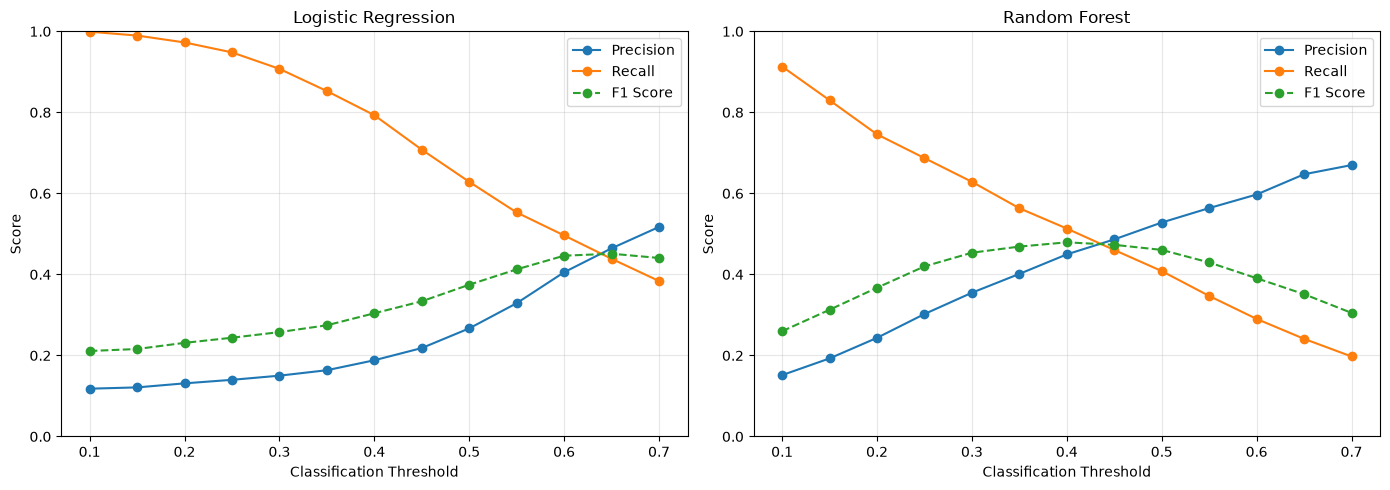

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, results in [
    ('Logistic Regression', logistic_threshold_results),
    ('Random Forest', forest_threshold_results)
]:
    ax = axes[0] if model_name == 'Logistic Regression' else axes[1]

    ax.plot(
        results['Threshold'],
        results['Precision'],
        marker='o',
        label='Precision'
    )

    ax.plot(
        results['Threshold'],
        results['Recall'],
        marker='o',
        label='Recall'
    )

    ax.plot(
        results['Threshold'],
        results['F1 Score'],
        marker='o',
        linestyle='--',
        label='F1 Score'
    )

    ax.set_title(model_name)
    ax.set_xlabel('Classification Threshold')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [22]:
logistic_best_threshold = 0.65
forest_best_threshold = 0.40

print("Logistic Regression threshold:", logistic_best_threshold)
print("Random Forest threshold:", forest_best_threshold)

Logistic Regression threshold: 0.65
Random Forest threshold: 0.4


In [23]:
logistic_val_tuned_predictions = (
    logistic_val_probabilities >= logistic_best_threshold
).astype(int)

forest_val_tuned_predictions = (
    forest_val_probabilities >= forest_best_threshold
).astype(int)

validation_tuned_results = pd.DataFrame({
    'Logistic Regression': evaluate_model(
        y_val,
        logistic_val_tuned_predictions,
        logistic_val_probabilities
    ),
    'Random Forest': evaluate_model(
        y_val,
        forest_val_tuned_predictions,
        forest_val_probabilities
    )
}).T

display(validation_tuned_results.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression,0.8751,0.4645,0.4386,0.4511,0.7699,0.4084
Random Forest,0.8695,0.4495,0.5132,0.4793,0.7987,0.4516


## 9. Final Model Evaluation

The selected classification thresholds will be evaluated on the held-out test dataset.

Both models will be retrained using the complete training dataset. The thresholds selected during validation will remain fixed.

The test dataset will be used only for this final evaluation.

In [24]:
# Create fresh pipelines
logistic_final_model = clone(logistic_model)
forest_final_model = clone(forest_model)

# Train using the complete training dataset
logistic_final_model.fit(X_train, y_train)
forest_final_model.fit(X_train, y_train)

print("Final models trained successfully.")

Final models trained successfully.


In [25]:
# Generate probability estimates
logistic_test_probabilities = logistic_final_model.predict_proba(X_test)[:, 1]
forest_test_probabilities = forest_final_model.predict_proba(X_test)[:, 1]

# Apply validation-selected thresholds
logistic_test_tuned_predictions = (
    logistic_test_probabilities >= logistic_best_threshold
).astype(int)

forest_test_tuned_predictions = (
    forest_test_probabilities >= forest_best_threshold
).astype(int)

print("Final test predictions generated successfully.")

Final test predictions generated successfully.


In [26]:
final_results = pd.DataFrame({
    'Logistic Regression (0.50)': evaluate_model(
        y_test,
        logistic_predictions,
        logistic_probabilities
    ),
    'Logistic Regression (0.65)': evaluate_model(
        y_test,
        logistic_test_tuned_predictions,
        logistic_test_probabilities
    ),
    'Random Forest (0.50)': evaluate_model(
        y_test,
        forest_predictions,
        forest_probabilities
    ),
    'Random Forest (0.40)': evaluate_model(
        y_test,
        forest_test_tuned_predictions,
        forest_test_probabilities
    )
}).T

display(final_results.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression (0.50),0.7557,0.2671,0.6238,0.3740,0.7722,0.4095
Logistic Regression (0.65),0.8748,0.4628,0.4348,0.4483,0.7722,0.4095
Random Forest (0.50),0.8858,0.5155,0.3922,0.4455,0.8028,0.4520
Random Forest (0.40),0.8700,0.4505,0.5076,0.4773,0.8028,0.4520


In [27]:
final_forest_cm = confusion_matrix(
    y_test,
    forest_test_tuned_predictions,
    labels=[0, 1]
)

print("Random Forest (threshold = 0.40)")
print("                 Predicted No  Predicted Yes")
print(f"Actual No        {final_forest_cm[0, 0]:>12}  {final_forest_cm[0, 1]:>13}")
print(f"Actual Yes       {final_forest_cm[1, 0]:>12}  {final_forest_cm[1, 1]:>13}")

Random Forest (threshold = 0.40)
                 Predicted No  Predicted Yes
Actual No                7330            655
Actual Yes                521            537


In [30]:
forest_permutation = permutation_importance(
    forest_final_model,
    X_test,
    y_test,
    scoring='average_precision',
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': forest_permutation.importances_mean,
    'Std': forest_permutation.importances_std
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

display(feature_importance.round(4).reset_index(drop=True))

,Feature,Importance,Std
0,month,0.1086,0.0061
1,contact,0.0928,0.0081
2,poutcome,0.0749,0.0051
3,housing,0.0358,0.0051
4,days_since_previous_contact,0.0317,0.0052
5,day,0.0278,0.0032
6,balance,0.0137,0.0059
7,contacts_before_current_call,0.0128,0.0029
8,marital,0.0109,0.0016
9,previous,0.0092,0.0022


### Feature Importance

Permutation importance was calculated on the held-out test set using
average precision as the scoring metric.

The most influential features were month, contact method, and the
outcome of the previous marketing campaign. These results suggest
that campaign timing, communication channel, and prior campaign
history provide substantial predictive information.

Housing status, days since the previous contact, and the day of the
month also contributed to model performance, while several
demographic and financial features had relatively small contributions.

These findings describe predictive associations in the historical
dataset and should not be interpreted as causal relationships.
Historical campaign practices may influence the observed patterns.


## 10. Business Recommendations and Model Limitations

### Business Objective

The objective of this project was to determine whether historical customer and marketing campaign information could help a bank identify customers more likely to subscribe to a term deposit.

The intended business application is to help marketing teams prioritize outreach rather than contact all customers indiscriminately.

### Final Model Selection

The Random Forest classifier with a classification threshold of 0.40 was selected as the preferred model.

On the held-out test dataset, it achieved:

| Metric | Result |
|---|---:|
| Accuracy | 87.00% |
| Precision | 45.05% |
| Recall | 50.76% |
| F1 Score | 47.73% |
| ROC-AUC | 80.28% |
| Average Precision | 45.20% |

The model's confusion matrix showed:

- 537 actual subscribers correctly identified.
- 521 actual subscribers missed.
- 655 non-subscribers incorrectly identified as potential subscribers.
- 7,330 non-subscribers correctly identified.

The model identified approximately 51% of actual subscribers while correctly classifying approximately 92% of non-subscribers.

Although its accuracy was lower than the 88.3% majority-class baseline, the model provided substantially more useful subscriber identification. The baseline predicted every customer as a non-subscriber and identified none of the actual subscribers.

### Key Findings

Permutation importance identified the following as the most influential features:

1. Month of contact
2. Contact method
3. Outcome of the previous marketing campaign
4. Housing loan status
5. Days since the previous contact

These findings suggest that campaign timing, communication channel, and prior campaign history contain substantial predictive information.

The results also demonstrate why accuracy alone is insufficient for evaluating an imbalanced classification problem. Precision, recall, F1 score, ROC-AUC, and average precision provide a more complete picture of model performance.

### Business Recommendations

Based on the analysis, the bank could consider the following actions:

1. **Prioritize customer outreach:** Use predicted subscription probabilities to help rank customers for marketing campaigns.
2. **Evaluate campaign timing:** Investigate the differences in subscription rates across contact months before making changes to campaign schedules.
3. **Review communication channels:** Examine whether different contact methods are associated with different conversion rates and whether those differences persist in future campaigns.
4. **Use previous campaign outcomes:** Consider prior campaign history when prioritizing customers for follow-up outreach.
5. **Test threshold choices:** Evaluate different classification thresholds based on actual outreach costs and the value of acquiring a new term-deposit customer.

The selected threshold of 0.40 provided the best F1 score among the thresholds tested on the validation dataset. It represents a reasonable starting point when balancing precision and recall, but it is not necessarily the most profitable threshold.

### Limitations and Considerations

Several limitations should be considered before using this model in a production environment.

- **Historical data:** The model was trained on historical campaign information. Customer behavior and marketing effectiveness may change over time.
- **Class imbalance:** Only approximately 11.7% of customers in the dataset subscribed to a term deposit. This makes accuracy alone an inadequate evaluation metric.
- **No causal inference:** Feature importance and observed subscription rates identify associations, not proof that changing a particular feature or marketing practice will increase subscriptions.
- **Limited generalizability:** The analysis uses one historical bank marketing dataset. Results should be validated against more recent campaigns and other customer populations.
- **Threshold selection:** The selected threshold optimizes F1 among the values tested, not financial return. A production decision should incorporate the cost of contacting customers and the expected value of subscriptions.
- **Potential bias:** Customer characteristics such as age, marital status, and education may influence predictions. Their use should be reviewed for fairness, privacy, and applicable regulatory requirements.
- **Prediction-time constraints:** Call duration was excluded because it is not available before a call takes place. The model is intended to support pre-call prioritization, not post-call prediction.

### Conclusion

This project demonstrates an end-to-end classification workflow using the UCI Bank Marketing dataset. Exploratory data analysis identified patterns in customer characteristics and previous marketing activity. Logistic Regression and Random Forest classifiers were developed, evaluated against a baseline, and compared using metrics appropriate for an imbalanced target.

The Random Forest model with a 0.40 classification threshold achieved the strongest F1 score on the held-out test dataset. Its results suggest that historical customer and campaign information can help prioritize potential term-deposit subscribers.

Further validation, threshold optimization based on business costs, and testing on newer campaign data would be necessary before operational deployment.
